In [1]:

!pip install -q pandas numpy scikit-learn matplotlib seaborn joblib


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.datasets import load_breast_cancer

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

print("Dataset loaded successfully!")

print("\nFirst five records:")
print(X.head())

print("\nDataset Shape:", X.shape)

print("\nTarget Distribution:")
print(y.value_counts())


Dataset loaded successfully!

First five records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radi

In [4]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)


Training Shape: (455, 30)
Testing Shape: (114, 30)


In [5]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-Fold Cross Validation Created!")


Stratified 5-Fold Cross Validation Created!


In [6]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

print("Four models created successfully!")

for name in models:
    print(name)


Four models created successfully!
Logistic Regression
Random Forest
SVM
Gradient Boosting


In [7]:

def create_pipeline(classifier):

    pipeline = Pipeline(
        steps=[
            (
                "imputer",
                SimpleImputer(strategy="median")
            ),

            (
                "scaler",
                StandardScaler()
            ),

            (
                "classifier",
                classifier
            )
        ]
    )

    return pipeline


print("Reusable preprocessing pipeline created!")


Reusable preprocessing pipeline created!


In [8]:

param_grids = {

    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10],
        "classifier__solver": ["liblinear"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_split": [2, 5]
    },

    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"]
    },

    "Gradient Boosting": {
        "classifier__n_estimators": [50, 100],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3]
    }
}

print("Hyperparameter grids created!")


Hyperparameter grids created!


In [10]:

scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

best_models = {}
comparison = []

for name, classifier in models.items():

    print("\nTraining:", name)

    pipeline = create_pipeline(classifier)

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring=scoring,
        refit="roc_auc",
        cv=cv,
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    comparison.append({
        "Model": name,
        "CV Precision": grid.cv_results_[
            "mean_test_precision"
        ][grid.best_index_],

        "CV Recall": grid.cv_results_[
            "mean_test_recall"
        ][grid.best_index_],

        "CV F1": grid.cv_results_[
            "mean_test_f1"
        ][grid.best_index_],

        "CV ROC-AUC": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print("Best Parameters:", grid.best_params_)
    print("Best CV ROC-AUC:", grid.best_score_)

print("\nAll four models trained and tuned!")



Training: Logistic Regression
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best Parameters: {'classifier__C': 1, 'classifier__solver': 'liblinear'}
Best CV ROC-AUC: 0.9959752321981423

Training: Random Forest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters: {'classifier__max_depth': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best CV ROC-AUC: 0.9902992776057792

Training: SVM
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Parameters: {'classifier__C': 0.1, 'classifier__kernel': 'linear'}
Best CV ROC-AUC: 0.9956656346749225

Training: Gradient Boosting
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 2, 'classifier__n_estimators': 100}
Best CV ROC-AUC: 0.9927760577915377

All four models trained and tuned!


In [11]:

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="CV ROC-AUC",
    ascending=False
)

print(comparison_df[
    [
        "Model",
        "CV Precision",
        "CV Recall",
        "CV F1",
        "CV ROC-AUC"
    ]
].to_string(index=False))


              Model  CV Precision  CV Recall    CV F1  CV ROC-AUC
Logistic Regression      0.982692   0.985965 0.984224    0.995975
                SVM      0.969640   0.992982 0.981015    0.995666
  Gradient Boosting      0.968653   0.971930 0.970219    0.992776
      Random Forest      0.962708   0.971930 0.966879    0.990299


In [12]:

test_results = []

for name, model in best_models.items():

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    test_results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_test, predictions
        ),

        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),

        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),

        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test, probabilities
        )
    })

test_results_df = pd.DataFrame(test_results)

print(test_results_df.to_string(index=False))


              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC
Logistic Regression  0.982456   0.986111 0.986111  0.986111 0.995701
      Random Forest  0.956140   0.958904 0.972222  0.965517 0.993386
                SVM  0.982456   0.986111 0.986111  0.986111 0.993717
  Gradient Boosting  0.947368   0.945946 0.972222  0.958904 0.990741


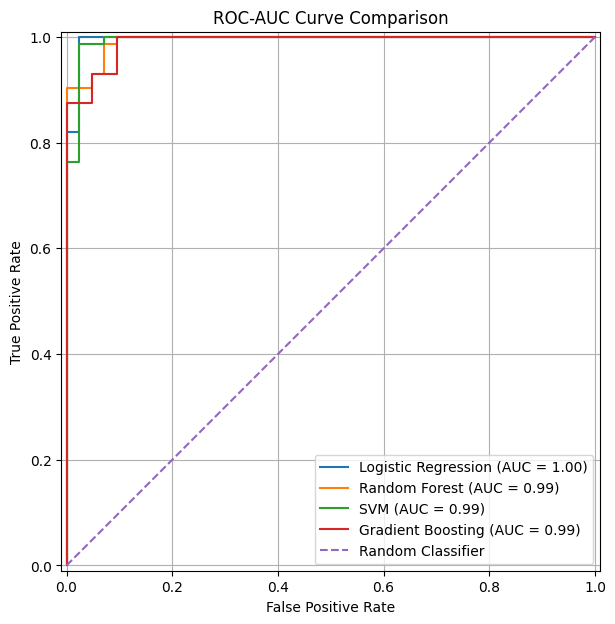

In [13]:

plt.figure(figsize=(9, 7))

ax = plt.gca()

for name, model in best_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC-AUC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.grid()
plt.show()


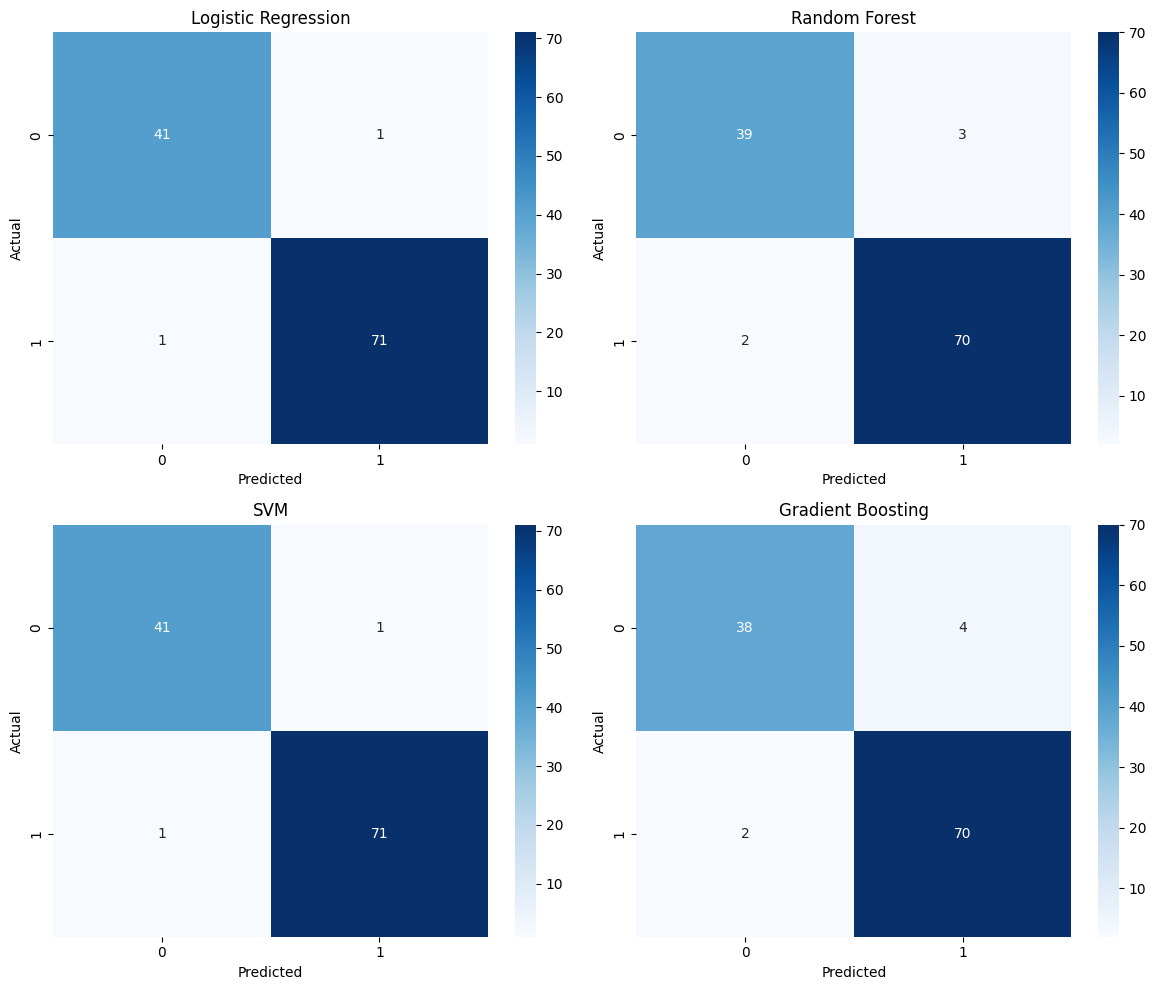

In [14]:

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

axes = axes.flatten()

for i, (name, model) in enumerate(best_models.items()):

    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [15]:

champion_name = comparison_df.iloc[0]["Model"]

champion_model = best_models[champion_name]

print("Champion Model:", champion_name)

print("\nChampion Model Parameters:")
print(comparison_df.iloc[0]["Best Parameters"])

print("\nChampion Test Performance:")
print(
    test_results_df[
        test_results_df["Model"] == champion_name
    ]
)


Champion Model: Logistic Regression

Champion Model Parameters:
{'classifier__C': 1, 'classifier__solver': 'liblinear'}

Champion Test Performance:
                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.982456   0.986111  0.986111  0.986111  0.995701


In [16]:

os.makedirs("models", exist_ok=True)

joblib.dump(
    champion_model,
    "models/champion_model.pkl"
)

print("Champion model saved successfully!")


Champion model saved successfully!


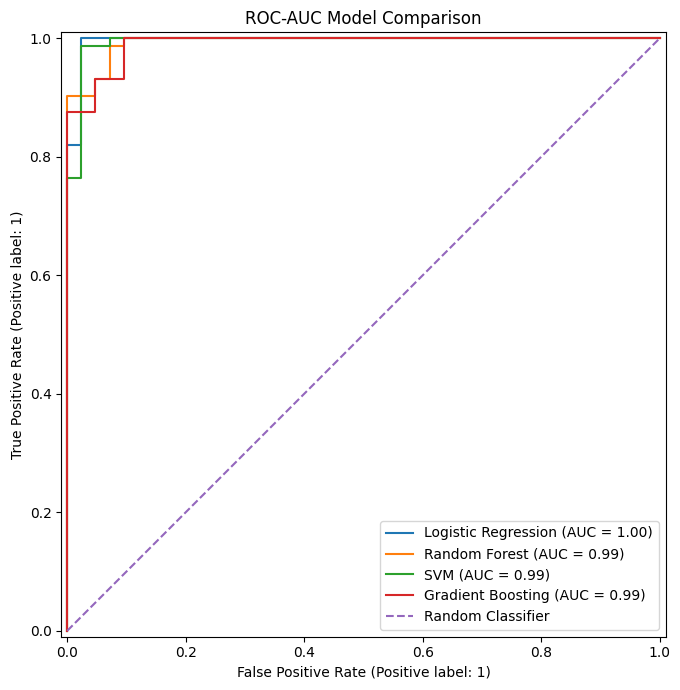

In [17]:

os.makedirs("results", exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 7))

for name, model in best_models.items():

    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

ax.set_title("ROC-AUC Model Comparison")
ax.legend()
fig.tight_layout()

fig.savefig(
    "results/roc_auc_curves.png",
    dpi=300
)

plt.show()
plt.close(fig)


In [19]:

test_results_df.to_csv(
    "results/model_comparison.csv",
    index=False
)

print("Model comparison CSV saved!")


Model comparison CSV saved!


In [20]:

import shutil

shutil.make_archive(
    "classification_project",
    "zip",
    ".",
    "models"
)

print("Model folder ZIP created!")


Model folder ZIP created!


In [21]:

from google.colab import files

files.download("models/champion_model.pkl")
files.download("results/roc_auc_curves.png")
files.download("results/confusion_matrices.png")
files.download("results/model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>